# Quantization — Lab Session

---
## Setup

In [ ]:
!pip -q install bitsandbytes datasets
!nvidia-smi --query-gpu=name,memory.total --format=csv

In [1]:
import os, re, gc, json, time, math, subprocess
from collections import Counter
import torch
import pandas as pd, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
DOG_PROMPT = "Describe a dog to someone who has never seen one, in three sentences."

tok = AutoTokenizer.from_pretrained(MODEL)
pd.set_option("display.max_colwidth", 120)

def cleanup():
    """Release cached GPU memory after `del model`."""
    gc.collect(); torch.cuda.empty_cache()

def gb(n_bytes):
    return n_bytes / 1e9

/home/lpozzi/Git/data-science-lectures/quantz/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## Block 1 · Model precision and memory

### 1.1 Numerical formats
A floating-point number = **sign** · **exponent** (range) · **mantissa** (precision).

| Format | Sign | Exponent | Mantissa |
|---|---|---|---|
| FP32 | 1 | 8 | 23 |
| FP16 | 1 | 5 | 10 |
| BF16 | 1 | 8 | 7 |

In [2]:
rows = []
for dt in [torch.float32, torch.float16, torch.bfloat16]:
    fi = torch.finfo(dt)
    rows.append({"dtype": str(dt)[6:], "bits": fi.bits, "max value": f"{fi.max:.3g}",
                 "smallest normal": f"{fi.tiny:.3g}", "precision near 1 (eps)": f"{fi.eps:.3g}"})
for dt in [torch.int8, torch.uint8]:
    ii = torch.iinfo(dt)
    rows.append({"dtype": str(dt)[6:], "bits": ii.bits, "max value": ii.max,
                 "smallest normal": f"min {ii.min}", "precision near 1 (eps)": 1})
pd.DataFrame(rows)

,dtype,bits,max value,smallest normal,precision near 1 (eps)
0,float32,32,3.4e+38,1.18e-38,1.19e-07
1,float16,16,6.55e+04,6.1e-05,0.000977
2,bfloat16,16,3.39e+38,1.18e-38,0.00781
3,int8,8,127,min -128,1
4,uint8,8,255,min 0,1


In [3]:
def show_bits(x):
    for dt in [torch.float32, torch.float16, torch.bfloat16, torch.int8, torch.uint8]:
        t = torch.tensor(x).to(dt)
        n = t.element_size() * 8
        bits = format(t.view(torch.int8 if n == 8 else torch.int16 if n == 16 else torch.int32).item() & (2**n - 1), f"0{n}b")
        print(f"{str(dt)[6:]:>9}: {bits}")

show_bits(8)


  float32: 01000001000000000000000000000000
  float16: 0100100000000000
 bfloat16: 0100000100000000
     int8: 00001000
    uint8: 00001000


In [4]:
# number of exponent bits per format (the rest after the sign are mantissa bits)
EXP_BITS = {torch.float32: 8, torch.float16: 5, torch.bfloat16: 8}

def bit_layout(x, dtype):
    """Show how x is stored: sign | exponent | mantissa, and the value actually stored."""
    t = torch.tensor([x], dtype=dtype)
    n = torch.finfo(dtype).bits
    raw = t.view(torch.int32 if n == 32 else torch.int16).item() & ((1 << n) - 1)
    b = format(raw, f"0{n}b")
    e = EXP_BITS[dtype]
    return f"{b[0]} | {b[1:1 + e]} | {b[1 + e:]}", t.item()

x = 3.14159
for dt in [torch.float32, torch.float16, torch.bfloat16]:
    layout, stored = bit_layout(x, dt)
    err = stored - x   # signed rounding error (python floats are float64, so this is accurate)
    print(f"{str(dt)[6:]:9} {layout:42} stored: {stored:.8f}  error: {err:+.2e}")



float32   0 | 10000000 | 10010010000111111010000     stored: 3.14159012  error: +1.18e-07
float16   0 | 10000 | 1001001000                     stored: 3.14062500  error: -9.65e-04
bfloat16  0 | 10000000 | 1001001                     stored: 3.14062500  error: -9.65e-04


In [5]:
for x in [70000.0, 1.001]:
    print(f"{x:>9}:  fp16 -> {torch.tensor(x).half().item()}   bf16 -> {torch.tensor(x).bfloat16().item()}")

  70000.0:  fp16 -> inf   bf16 -> 70144.0
    1.001:  fp16 -> 1.0009765625   bf16 -> 1.0


- **FP16**: good precision, small range: 70,000 overflows to `inf`.
- **BF16**: same range as FP32, little precision: 1.001 becomes 1.0. Training prefers BF16 (no overflow)

### 1.2 A model in memory
🔮 **Predict:** how much GPU memory does a 1.5B-parameter model need in FP32? In FP16?

In [6]:
rows, model_fp16 = [], None
for dt in [torch.float32, torch.bfloat16, torch.float16]:
    cleanup(); before = torch.cuda.memory_allocated()
    m = AutoModelForCausalLM.from_pretrained(MODEL, dtype=dt, device_map="cuda")
    rows.append({"dtype": str(dt)[6:], "GPU memory (GB)": gb(torch.cuda.memory_allocated() - before),
                 "bytes per parameter": torch.finfo(dt).bits // 8})
    if dt == torch.float16:
        model_fp16 = m                          # keep it: it is the baseline for Block 2
    else:
        del m
cleanup()
pd.DataFrame(rows).round(3)

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2045.28it/s]


,dtype,GPU memory (GB),bytes per parameter
0,float32,0.538,4
1,bfloat16,0.269,2
2,float16,0.269,2


In [7]:
n = sum(p.numel() for p in model_fp16.parameters())
print(f"{n / 1e9:.2f}B parameters")
for name, bits in [("FP32", 32), ("FP16 / BF16", 16), ("INT8", 8), ("INT4", 4)]:
    print(f"  {name:12} {n * bits / 8 / 1e9:5.2f} GB")

# Where are the parameters?
groups = Counter()
for name, p in model_fp16.named_parameters():
    key = "embeddings" if "embed" in name else ("attention" if "self_attn" in name else
          "MLP" if "mlp" in name else "norms / other")
    groups[key] += p.numel()
pd.Series(groups).div(n).mul(100).round(1).rename("% of parameters").to_frame()

0.13B parameters
  FP32          0.54 GB
  FP16 / BF16   0.27 GB
  INT8          0.13 GB
  INT4          0.07 GB


,% of parameters
embeddings,21.0
attention,19.7
MLP,59.2
norms / other,0.0


The vocabulary is large, so the **embedding matrix** alone is a big share of a small model.
The attention projections and MLP projections of every layer hold the rest: these **linear layers** are what quantization targets.

### 1.3 Symmetric quantization
Map $[-\max|x|,\ \max|x|]$ to $[-127, 127]$ with one **scale**:

$$s = \frac{\max|x|}{2^{b-1}-1} \qquad q = \text{round}(x / s) \qquad \hat{x} = q \cdot s$$

### Asymmetric quantization
Map $[\min x,\ \max x]$ to $[0, 255]$ with a **scale** and a **zero point**:

$$s = \frac{\max x - \min x}{2^b - 1} \qquad z = \text{round}(-\min x / s) \qquad q = \text{round}(x/s) + z \qquad \hat{x} = (q - z)\cdot s$$

min -6.01  max 8.00  absmax 8.00


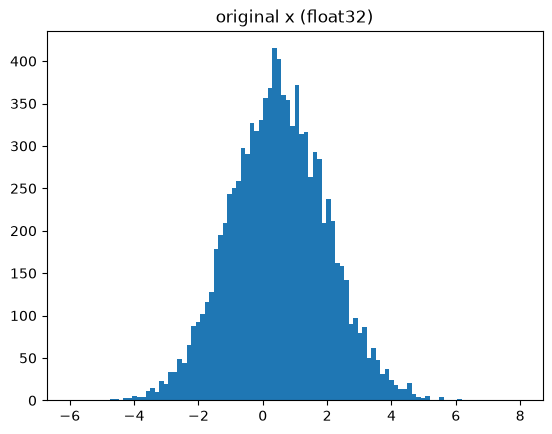

In [9]:
torch.manual_seed(0)
x = torch.randn(10_000) * 1.5 + 0.5   # not centered on 0
x[0] = 8.0                            # one outlier
print(f"min {x.min():.2f}  max {x.max():.2f}  absmax {x.abs().max():.2f}")

plt.hist(x, bins=100); plt.title("original x (float32)"); plt.show()


In [10]:
qmax = 127
absmax = x.abs().max()
scale = absmax / qmax
print(f"scale = {scale:.4f}   (one integer step = {scale:.4f} in float)")

scale = 0.0630   (one integer step = 0.0630 in float)


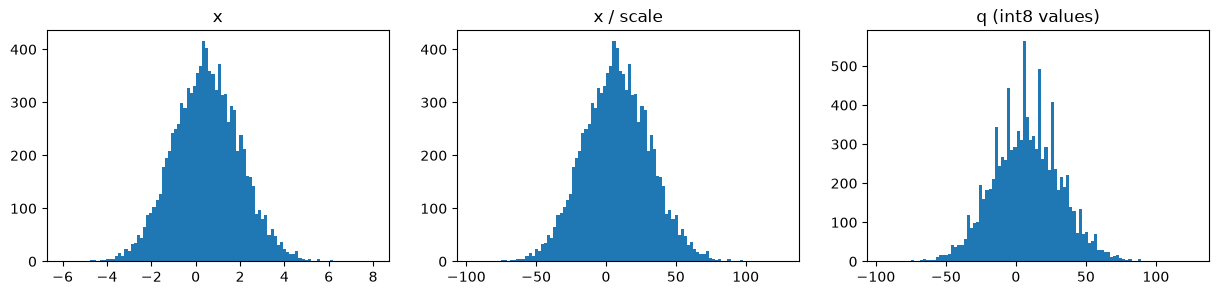

In [11]:
x_scaled = x / scale                           # now in [-127, 127], still float
q  = torch.round(x_scaled)               # snap to integers: this is where information is lost

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for a, v, t in zip(ax, [x, x_scaled, q], ["x", "x / scale", "q (int8 values)"]):
    a.hist(v, bins=100); a.set_title(t)
plt.show()


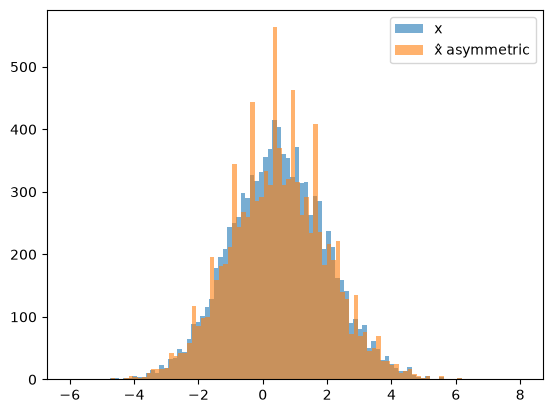

max |error| = 0.0315   (scale/2 = 0.0315)


In [12]:
# what quantization costs you after you convert back to float.

x_hat = q * scale
err = x - x_hat

plt.hist(x, bins=100, alpha=.6, label="x"); plt.hist(x_hat, bins=100, alpha=.6, label="x̂ asymmetric")
plt.legend(); plt.show()
print(f"max |error| = {err.abs().max():.4f}   (scale/2 = {scale/2:.4f})")


range [-6.01, 8.00]   scale = 0.0550
zero point = 109   (real 0.0 is stored as integer 109)


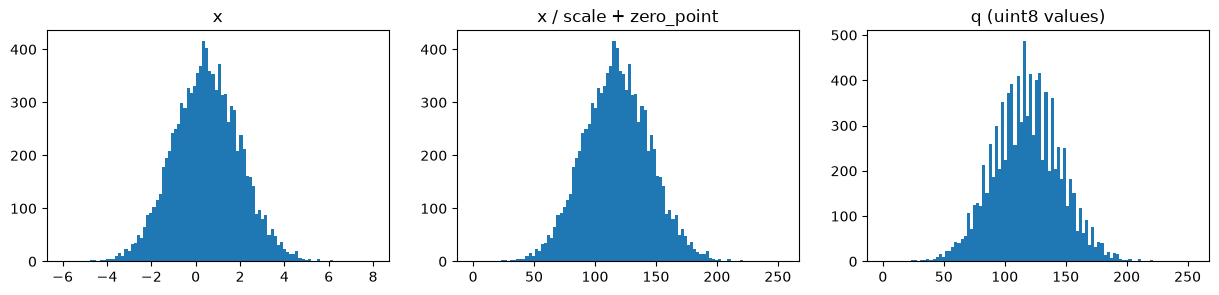

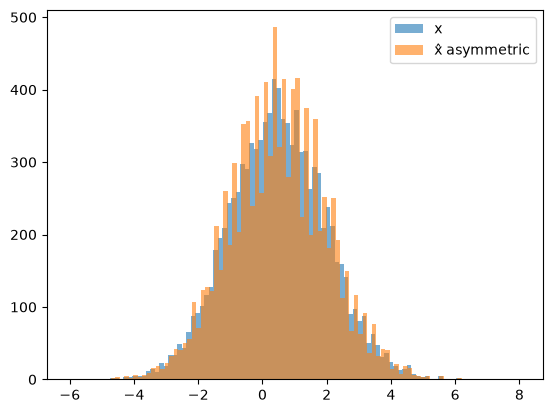

max |error| = 0.0275   (scale/2 = 0.0275)


In [13]:
qmin, qmax = 0, 255 # full range of an unsigned 8-bit integer (uint8)
xmin, xmax = x.min(), x.max()
scale_a = (xmax - xmin) / (qmax - qmin)
print(f"range [{xmin:.2f}, {xmax:.2f}]   scale = {scale_a:.4f}")

zero_point = torch.round(-xmin / scale_a)
print(f"zero point = {zero_point:.0f}   (real 0.0 is stored as integer {zero_point:.0f})")

x_scaled = x / scale_a                        # float, spans about [xmin/scale, xmax/scale]
x_shift  = x_scaled + zero_point              # shifted so xmin lands on 0
q_a      = torch.clamp(torch.round(x_shift), qmin, qmax)

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for a, v, t in zip(ax, [x, x_shift, q_a], ["x", "x / scale + zero_point", "q (uint8 values)"]):
    a.hist(v, bins=100); a.set_title(t)
plt.show()

x_hat_a = (q_a - zero_point) * scale_a
err_a = x - x_hat_a

plt.hist(x, bins=100, alpha=.6, label="x"); plt.hist(x_hat_a, bins=100, alpha=.6, label="x̂ asymmetric")
plt.legend(); plt.show()
print(f"max |error| = {err_a.abs().max():.4f}   (scale/2 = {scale_a/2:.4f})")



In [14]:
def quantize_symmetric(x, bits=8, dim=None):
    """One scale per tensor (dim=None) or per row (dim=1). Returns integers and scale."""
    qmax = 2 ** (bits - 1) - 1

    #  per-tensor quantization, or per-channel (or per-token) quantization
    absmax = x.abs().max() if dim is None else x.abs().amax(dim=dim, keepdim=True)
    scale = absmax / qmax
    q = torch.clamp(torch.round(x / scale), -qmax, qmax)
    return q, scale

def dequantize_symmetric(q, scale):
    return q * scale

def quantize_asymmetric(x, bits=8):
    qmin, qmax = 0, 2 ** bits - 1
    scale = (x.max() - x.min()) / (qmax - qmin)
    zero_point = torch.round(-x.min() / scale)
    q = torch.clamp(torch.round(x / scale) + zero_point, qmin, qmax)
    return q, scale, zero_point

def dequantize_asymmetric(q, scale, zero_point):
    return (q - zero_point) * scale

🔮 **Predict:** activations after a ReLU are all **positive**. Which scheme loses less information?

In [15]:
def mean_error(x, scheme, bits=8):
    if scheme == "symmetric":
        q, s = quantize_symmetric(x, bits); return (x - dequantize_symmetric(q, s)).abs().mean().item()
    q, s, z = quantize_asymmetric(x, bits); return (x - dequantize_asymmetric(q, s, z)).abs().mean().item()

torch.manual_seed(0)
cases = {"centered (like weights)": torch.randn(10_000), "all positive (like ReLU outputs)": torch.rand(10_000) * 6}
pd.DataFrame({name: {s: mean_error(v, s) for s in ["symmetric", "asymmetric"]} for name, v in cases.items()}).T

,symmetric,asymmetric
centered (like weights),0.008547,0.008316
all positive (like ReLU outputs),0.011863,0.005890


With positive values, symmetric quantization **wastes half of its range** (the negative integers are never used), so its error doubles.

### The outlier problem
🔮 **Predict:** the vector `[120, 0.01, -0.2, 0.0]` (from the lecture). What happens to the small values?

In [16]:
x = torch.tensor([120.0, 0.01, -0.2, 0.0])
q, s = quantize_symmetric(x)
print("x        :", x.tolist())
print("scale    :", round(s.item(), 4))
print("q (int8) :", q.int().tolist())
print("x̂        :", dequantize_symmetric(q, s).tolist())

x        : [120.0, 0.009999999776482582, -0.20000000298023224, 0.0]
scale    : 0.9449
q (int8) : [127, 0, 0, 0]
x̂        : [120.0, 0.0, -0.0, 0.0]


**One outlier sets the scale for everyone**: the small values all collapse to 0. This is the problem LLM.int8() solves (Block 2).

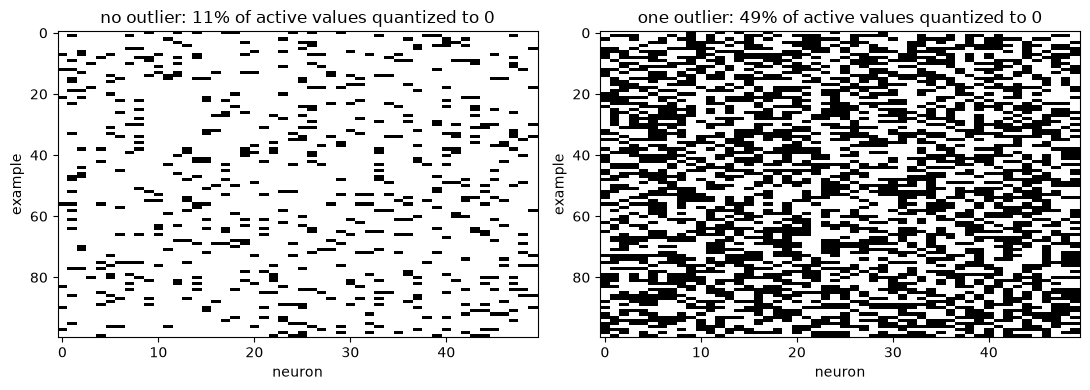

In [17]:
def fake_quant(h, bits=4):
    """Quantize + dequantize in the forward pass; gradient passes straight through (STE)."""
    qmax = 2 ** (bits - 1) - 1                 # largest integer level (7 for 4 bits)
    scale = h.abs().max() / qmax               # symmetric absmax scale: ONE scale for the whole tensor,
                                               # so a single outlier makes it large for everyone
    # round to integer levels, clamp to the valid range, then convert back to float
    hq = torch.clamp(torch.round(h / scale), -qmax, qmax) * scale
    # straight-through estimator (STE): the forward value is hq, but the backward pass treats
    # the operation as the identity (torch.round alone would give zero gradient everywhere)
    return h + (hq - h).detach()


def run(outlier, bits=4):
    torch.manual_seed(0)                       # same data in both runs, so only the outlier differs
    X, y = torch.randn(100, 20), torch.randn(100, 1)    # 100 examples, 20 features, 1 target each
    if outlier: X[0] *= 30                     # make example 0 huge: this is the outlier
    W1 = torch.randn(20, 50) / 20 ** 0.5       # fixed hidden-layer weights (not trained here)
    W2 = torch.randn(50, 1, requires_grad=True)  # output weights: we look at THEIR gradient

    # forward pass
    h  = torch.relu(X @ W1)                    # hidden activations (100 examples x 50 neurons)
    hq = fake_quant(h, bits)                   # what the quantized network actually sees
    loss = ((hq @ W2 - y) ** 2).mean()         # mean squared error

    # backward pass: fills W2.grad. For each neuron, dL/dW2 = (its activation) x (error signal),
    # so a neuron whose quantized activation is 0 for every example gets exactly 0 gradient
    loss.backward()

    lost = (hq == 0) & (h > 0)                 # was active before quantization, zero after
    return lost.detach(), W2.grad.abs().squeeze()   # per-neuron gradient magnitude


fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, (outlier, title) in enumerate([(False, "no outlier"), (True, "one outlier")]):
    lost, g = run(outlier)

    # grid of examples x neurons; black = value destroyed by quantization
    # (like Karpathy's tanh saturation plot, but here the cause is the coarse rounding)
    ax[i].imshow(~lost, cmap="gray", aspect="auto", interpolation="nearest")   # white = fine, black = value lost
    ax[i].set_title(f"{title}: {lost.float().mean():.0%} of active values quantized to 0")
    ax[i].set_xlabel("neuron"); ax[i].set_ylabel("example")
plt.tight_layout(); plt.show()



### Granularity: per tensor, per row, per group
Real methods use **many scales**: one per row (output channel), or one per **group** of 128 weights (GPTQ, AWQ, GGUF).

In [18]:
# first attention layer's query projection: a real weight matrix, in float32 so the math is exact
W = model_fp16.model.layers[0].self_attn.q_proj.weight.float()

def rel_error(W, bits, granularity):
    """Quantize W, dequantize it, and return ||W - W_hat|| / ||W|| (error relative to weight size)."""
    if granularity == "per tensor":
        q, s = quantize_symmetric(W, bits)                # one scale for the whole matrix
    elif granularity == "per row":
        q, s = quantize_symmetric(W, bits, dim=1)         # one scale per row (output channel)
    else:                                                 # groups of 128 consecutive weights
        G = W.reshape(-1, 128)                            # each row of G is one group of 128 weights
        q, s = quantize_symmetric(G, bits, dim=1)         # one scale per group
        return ((G - q * s).norm() / G.norm()).item()     # compare with G, which has the grouped shape
    return ((W - q * s).norm() / W.norm()).item()         # q * s is the dequantized matrix W_hat

# table: rows = granularity, columns = bit width, cells = relative error
# finer granularity (smaller groups) -> a local outlier affects fewer weights -> lower error
pd.DataFrame({bits: {g: rel_error(W, bits, g) for g in ["per tensor", "per row", "per group (128)"]}
              for bits in [8, 4, 3]}).rename(columns=lambda b: f"INT{b}").style.format("{:.2%}")


,INT8,INT4,INT3
per tensor,4.22%,61.82%,90.31%
per row,1.01%,17.74%,38.97%
per group (128),0.82%,14.62%,32.35%


- More bits → less error. More scales (finer granularity) → less error, at the cost of storing the scales.
- At 4 bits, per-tensor scaling is unusable; per-group scaling is what makes 4-bit LLMs work.

✏️ **Try at home:** implement asymmetric **per-group** quantization and compare it with the symmetric one at 3 bits.

---
## Block 2 · Quantizing with bitsandbytes

[bitsandbytes](https://huggingface.co/docs/transformers/quantization/bitsandbytes) quantizes the weights **while loading** the model:
no calibration data, no extra step.

| Mode | Paper | Weights | Matrix multiplication |
|---|---|---|---|
| `load_in_8bit` | LLM.int8() (Dettmers et al., 2022) | INT8, one scale per row | INT8 for normal features; **FP16 for outlier features** (> threshold 6.0) |
| `load_in_4bit` | QLoRA (Dettmers et al., 2023) | **NF4** (4-bit NormalFloat), one scale per block of 64 | weights dequantized to FP16 on the fly |

In [19]:
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

cfg_int8 = BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
cfg_nf4 = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)

def gb(n_bytes):
    return n_bytes / 1e9

def load_quantized(config):
    cleanup(); before = torch.cuda.memory_allocated()
    m = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=config, dtype=torch.float16, device_map="cuda")
    return m, gb(torch.cuda.memory_allocated() - before)

model_int8, mem_int8 = load_quantized(cfg_int8)
model_nf4, mem_nf4 = load_quantized(cfg_nf4)
models = {"FP16": model_fp16, "INT8 (LLM.int8)": model_int8, "NF4 (4-bit)": model_nf4}

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 404.40it/s]


🔮 **Predict:** INT8 should be 2x smaller than FP16, NF4 4x smaller. Will it be?

In [20]:
memory = pd.DataFrame({name: {"footprint (GB)": gb(m.get_memory_footprint())} for name, m in models.items()}).T
memory["vs FP16"] = (memory.loc["FP16", "footprint (GB)"] / memory["footprint (GB)"]).map("{:.2f}x smaller".format)
memory.round(2)

,footprint (GB),vs FP16
FP16,0.27,1.00x smaller
INT8 (LLM.int8),0.16,1.65x smaller
NF4 (4-bit),0.11,2.45x smaller


In [ ]:
@torch.no_grad()
def chat(model, prompt, max_new_tokens=100):
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True)["input_ids"].to("cuda")
    out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)

for name, m in models.items():
    print(f"=== {name} ===\n{chat(m, DOG_PROMPT)}\n")

### A number for quality: perplexity
**Perplexity measures how surprised a language model is by a text.** Lower is better.

The model reads a text token by token. At each position it assigns a probability to the token that actually comes next. A good model gives high probability to the real next token, and a bad model gives low probability.

**How it is computed**

1. For each token, take the loss: $-\log p(\text{real next token})$. This is large when the model was surprised.
2. Average that loss over all tokens in the text.
3. Take the exponential:

$$\text{perplexity} = \exp\left(\frac{1}{N}\sum_{i=1}^{N} -\log p(x_i \mid x_{<i})\right)$$

**How to read it**
- The minimum is 1, which means the model always predicts the next token with certainty.
- The number depends on the text and the tokenizer, so only compare models evaluated on the **same data with the same tokenizer**.

**Why we use it here**

Quantization changes the weights, so the model's predictions shift slightly. Perplexity gives one number for how much quality was lost:

- FP16 is the baseline.
- If INT8 or NF4 raise the perplexity, the model has become worse at predicting text.
- A small increase means the quantization is nearly free. A large one means real damage, like the repetition loop we saw in the NF4 answer.

We evaluate in non-overlapping windows of 1024 tokens and average the loss over them. The sample is small to keep the class fast, so small differences between models can be noise.


In [ ]:
from itertools import islice
from datasets import load_dataset

# stream a tiny dataset: only the first 200 stories are fetched, not the whole file
ds = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)
text = "\n\n".join(r["text"] for r in islice(ds, 200))
eval_ids = tok(text, return_tensors="pt").input_ids[:, :4_096]       # 4 windows of 1024 tokens
print(eval_ids.shape)                                                # should be (1, 4096)

@torch.no_grad()
def perplexity(model, ids, window=1024):
    # average the loss over non-overlapping windows, then exp(mean loss) = perplexity
    losses = [model(ids[:, i:i + window].to("cuda"), labels=ids[:, i:i + window].to("cuda")).loss.item()
              for i in range(0, ids.shape[1] - window + 1, window)]
    return math.exp(sum(losses) / len(losses))

summary = memory[["footprint (GB)"]].copy()
summary["perplexity"] = [perplexity(m, eval_ids) for m in models.values()]
summary.round(2)


**What to notice**
- Memory goes down a lot, perplexity goes up a little: weight quantization to 8 and 4 bits is cheap in quality.
- bitsandbytes is a tool to **fit** a model in memory (e.g. QLoRA fine-tuning), not to serve it fast:
  weights are dequantized (or split into INT8 + FP16 parts) at every step.

**When do we need activations and calibration?**
- bitsandbytes, GPTQ and AWQ quantize **weights only**: they are fixed, so their scales are computed once.
- Quantizing **activations** too (W8A8, FP8) uses integer or FP8 tensor cores and speeds up compute-bound workloads,
  but activations change with every input: their scales are either computed **on the fly** (dynamic, like LLM.int8())
  or estimated in advance on **calibration data** (static).
- Calibration data is also what **GPTQ** and **AWQ** use to decide *how* to quantize the weights to 4 bits with less error: next block.

In [ ]:
# Free the GPU
for name in ["model_fp16", "model_int8", "model_nf4", "models", "m", "layer", "W"]:
    globals().pop(name, None)                  # drop every reference to the models
cleanup()
print(f"GPU memory still allocated by this notebook: {gb(torch.cuda.memory_allocated()):.2f} GB")

---
## Block 3 · Pre-quantized models

GPTQ and AWQ need **calibration data** and some GPU time to quantize a model.
You don't run them yourself: the publisher quantizes the model **once** and uploads the result to Hugging Face,
next to the original. You just pick the version you want.

🔮 **Predict:** the original Qwen2.5-1.5B-Instruct is ~3.1 GB. How big are the 4-bit versions?

In [ ]:
from huggingface_hub import HfApi, hf_hub_download

QWEN = "Qwen/Qwen2.5-1.5B-Instruct"
CHECKPOINTS = {"original (BF16)": QWEN,
               "GPTQ-Int4":       QWEN + "-GPTQ-Int4",
               "AWQ":             QWEN + "-AWQ"}

api, rows = HfApi(), []
for name, repo in CHECKPOINTS.items():
    # size of the weight files on the Hub (metadata only, nothing is downloaded)
    files = api.model_info(repo, files_metadata=True).siblings
    size = sum(f.size for f in files if f.rfilename.endswith(".safetensors"))
    # the quantization settings are in config.json (a few KB)
    qcfg = json.load(open(hf_hub_download(repo, "config.json"))).get("quantization_config", {})
    rows.append({"checkpoint": name, "repo": repo, "download (GB)": gb(size),
                 "method": qcfg.get("quant_method", "none"),
                 "bits": qcfg.get("bits", 16),
                 "group_size": qcfg.get("group_size", "-")})

ckpt = pd.DataFrame(rows).set_index("checkpoint")
ckpt["vs original"] = (ckpt["download (GB)"].iloc[0] / ckpt["download (GB)"]).map("{:.1f}x smaller".format)
ckpt.round(2)

- **Same model, already quantized**: 4 bits, one scale per **group of 128** weights (as in Block 1). Someone else ran the calibration.
- Not exactly 4x smaller: the **embedding matrix** stays in 16 bits (Block 1: it is a big share of a small model),
  and the scales take space too.
- Using one is just a model name: `vllm serve Qwen/Qwen2.5-1.5B-Instruct-AWQ`; vLLM reads `quantization_config` and does the rest.

### Which format for which job?

| You want to... | Format | Runtime |
|---|---|---|
| Fine-tune a large model on a small GPU | bitsandbytes NF4 (QLoRA) | transformers + PEFT |
| Serve many users on a GPU | GPTQ / AWQ (or FP8) | vLLM, SGLang |
| Run locally: laptop, CPU, Mac, phone | GGUF | llama.cpp, Ollama, LM Studio |